In [1]:
!pip install torch torchvision numpy pandas matplotlib scikit-learn

In [2]:
import torch 
import torch.nn as nn
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt  

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Pytorch Version",torch.__version__)
print("Cuda Availabe",torch.cuda.is_available())

Pytorch Version 2.14.1+cu130
Cuda Availabe True


In [3]:
data = fetch_covtype()

In [4]:
X = data.data
# Forest cover type classes are 1-indexed (1 to 7).
# Shift to 0 to 6 for PyTorch CrossEntropyLoss
y = data.target - 1

print("Features", X.shape)
print("Labels", y.shape)
print("Unique Class", np.unique(y))

Features (581012, 54)
Labels (581012,)
Unique Class [0 1 2 3 4 5 6]


In [5]:
# Train test Split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training Size",X_train.shape)
print("Testing Size",X_test.shape)

Training Size (464809, 54)
Testing Size (116203, 54)


In [6]:
scaler = StandardScaler() #What is Standard Scalr ? how it help ? do u know any other scaling techniuqe
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test) # why not fit transform in x_test ?

print(X_train.shape)
print(y_train.shape)

(464809, 54)
(464809,)


In [7]:
# Convert the data into tensors 

X_train_tensor = torch.tensor(
    X_train, dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test, dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train, dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test, dtype=torch.long
)

print(X_train_tensor.shape)
print(y_train_tensor.shape)

torch.Size([464809, 54])
torch.Size([464809])


In [8]:
# Creating the Neural Network 

class ForestNet(nn.Module):
    def __init__(self):
        super().__init__() # why super init .. ??

        self.layer1 = nn.Linear(54,128)
        self.relu1 = nn.ReLU()

        self.layer2 = nn.Linear(128,64)
        self.relu2 = nn.ReLU()

        self.output = nn.Linear(64,7)

    def forward(self,x):
        x = self.layer1(x)
        x = self.relu1(x)
        x = self.layer2(x)
        x = self.relu2(x)
        x = self.output(x)
        return x

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = ForestNet().to(device)

print(model)
print(device)

ForestNet(
  (layer1): Linear(in_features=54, out_features=128, bias=True)
  (relu1): ReLU()
  (layer2): Linear(in_features=128, out_features=64, bias=True)
  (relu2): ReLU()
  (output): Linear(in_features=64, out_features=7, bias=True)
)
cuda


In [10]:
from torchinfo import summary

summary(model, input_size=(32, 54))

Layer (type:depth-idx)                   Output Shape              Param #
ForestNet                                [32, 7]                   --
├─Linear: 1-1                            [32, 128]                 7,040
├─ReLU: 1-2                              [32, 128]                 --
├─Linear: 1-3                            [32, 64]                  8,256
├─ReLU: 1-4                              [32, 64]                  --
├─Linear: 1-5                            [32, 7]                   455
Total params: 15,751
Trainable params: 15,751
Non-trainable params: 0
Total mult-adds (M): 0.50
Input size (MB): 0.01
Forward/backward pass size (MB): 0.05
Params size (MB): 0.06
Estimated Total Size (MB): 0.12

In [11]:
# Sample testing 

sample = X_train_tensor[:5].to(device)
print(sample.shape)

output = model(sample)
print(output.shape)

print(output)

torch.Size([5, 54])
torch.Size([5, 7])
tensor([[-0.1246, -0.0769,  0.1284, -0.0996,  0.0728,  0.0405, -0.1745],
        [-0.1015, -0.0448,  0.1605, -0.0450,  0.0943,  0.0940, -0.1553],
        [-0.1519,  0.0401,  0.1652,  0.2943,  0.3139, -0.0034, -0.1208],
        [-0.1352, -0.0460,  0.1943, -0.0205,  0.0511, -0.0140, -0.0472],
        [-0.1933, -0.0769,  0.1002, -0.1276,  0.0202,  0.0369, -0.0695]],
       device='cuda:0', grad_fn=<AddmmBackward0>)


In [12]:
criterion = nn.CrossEntropyLoss()

sample_labels = y_train_tensor[:5].to(device)

loss = criterion(output, sample_labels)

print("Initial Loss:", loss.item())

Initial Loss: 2.023879289627075


In [13]:
print("Min label:", y_train_tensor.min().item())
print("Max label:", y_train_tensor.max().item())

print("Unique labels:", torch.unique(y_train_tensor))

Min label: 0
Max label: 6
Unique labels: tensor([0, 1, 2, 3, 4, 5, 6])


In [18]:
model = ForestNet().to(device)
criterion = nn.CrossEntropyLoss()

sample = X_train_tensor[:5].to(device)
sample_labels = y_train_tensor[:5].to(device)

output = model(sample)
loss = criterion(output,sample_labels)
print(loss.item())

loss.backward()

1.9932960271835327


In [21]:
print(model.named_parameters())

<generator object Module.named_parameters at 0x7030ad11de00>


In [22]:
for name,param in model.named_parameters():
    print("Layers", name)
    print("Weight Shape",param.shape)
    print("Gradient Shape",param.grad.shape)
    print("Gradient Norm",param.grad.norm().item())

Layers layer1.weight
Weight Shape torch.Size([128, 54])
Gradient Shape torch.Size([128, 54])
Gradient Norm 0.5900768041610718
Layers layer1.bias
Weight Shape torch.Size([128])
Gradient Shape torch.Size([128])
Gradient Norm 0.06625247746706009
Layers layer2.weight
Weight Shape torch.Size([64, 128])
Gradient Shape torch.Size([64, 128])
Gradient Norm 0.892932116985321
Layers layer2.bias
Weight Shape torch.Size([64])
Gradient Shape torch.Size([64])
Gradient Norm 0.15830442309379578
Layers output.weight
Weight Shape torch.Size([7, 64])
Gradient Shape torch.Size([7, 64])
Gradient Norm 0.6895700693130493
Layers output.bias
Weight Shape torch.Size([7])
Gradient Shape torch.Size([7])
Gradient Norm 0.3715071678161621


In [23]:
layers = []
graident_norms = []

for name, param in model.named_parameters():
    if param.grad is not None:
        layers.append(name)
        graident_norms.append(param.grad.norm().item())



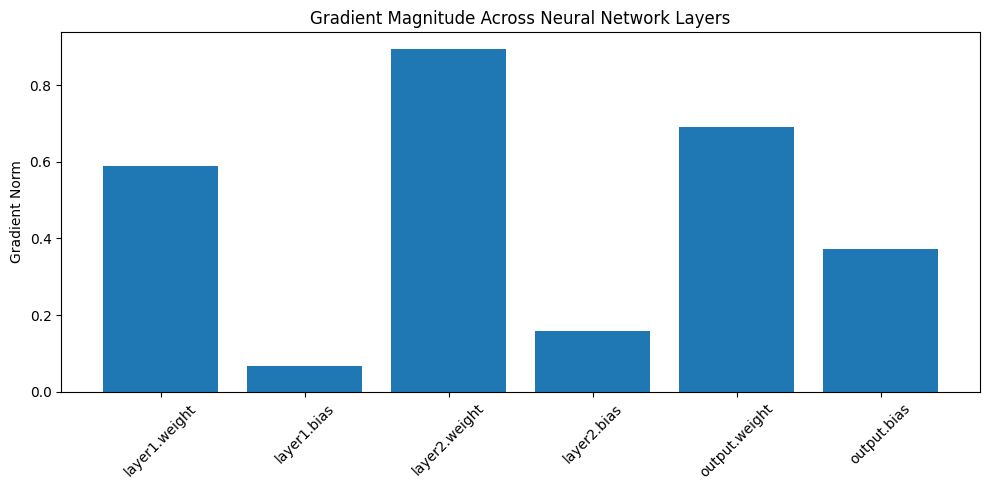

In [27]:
plt.figure(figsize=(10,5))
plt.bar(layers,graident_norms)
plt.xticks(rotation=45)
plt.ylabel("Gradient Norm")
plt.title("Gradient Magnitude Across Neural Network Layers")

plt.tight_layout()
plt.show()

In [28]:
# Fresh model
model = ForestNet().to(device)

criterion = nn.CrossEntropyLoss()

learning_rate = 0.01

sample = X_train_tensor[:64].to(device)
labels = y_train_tensor[:64].to(device)

# Forward
output = model(sample)

# Loss
loss = criterion(output, labels)

# Backward
loss.backward()

# Manual weight update
with torch.no_grad():

    for param in model.parameters():

        param -= learning_rate * param.grad

        param.grad.zero_()

print("Loss before update:", loss.item())

Loss before update: 2.0114145278930664


In [29]:
new_output = model(sample)

new_loss = criterion(new_output, labels)

print("Loss after update:", new_loss.item())

Loss after update: 2.00364089012146


In [34]:
import copy

learning_rate = 0.01
epochs = 20

model_gd = ForestNet().to(device)

# Save initial weights for fair comparison later
initial_weights = copy.deepcopy(model_gd.state_dict())

criterion = nn.CrossEntropyLoss()

# Entire training dataset
X_full = X_train_tensor.to(device)
y_full = y_train_tensor.to(device)

loss_history_gd = []

In [35]:
for epoch in range(epochs):
    output = model_gd(X_full)
    loss = criterion(output,y_full)

    model_gd.zero_grad()
    loss.backward()

    with torch.no_grad():
        for param in model_gd.parameters():
            param -= learning_rate * param.grad

    loss_history_gd.append(loss.item())

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {loss.item():.6f}"
    )


Epoch [1/20] Loss: 1.981821
Epoch [2/20] Loss: 1.976376
Epoch [3/20] Loss: 1.970992
Epoch [4/20] Loss: 1.965667
Epoch [5/20] Loss: 1.960399
Epoch [6/20] Loss: 1.955185
Epoch [7/20] Loss: 1.950025
Epoch [8/20] Loss: 1.944915
Epoch [9/20] Loss: 1.939855
Epoch [10/20] Loss: 1.934842
Epoch [11/20] Loss: 1.929874
Epoch [12/20] Loss: 1.924949
Epoch [13/20] Loss: 1.920066
Epoch [14/20] Loss: 1.915222
Epoch [15/20] Loss: 1.910417
Epoch [16/20] Loss: 1.905648
Epoch [17/20] Loss: 1.900915
Epoch [18/20] Loss: 1.896215
Epoch [19/20] Loss: 1.891548
Epoch [20/20] Loss: 1.886913


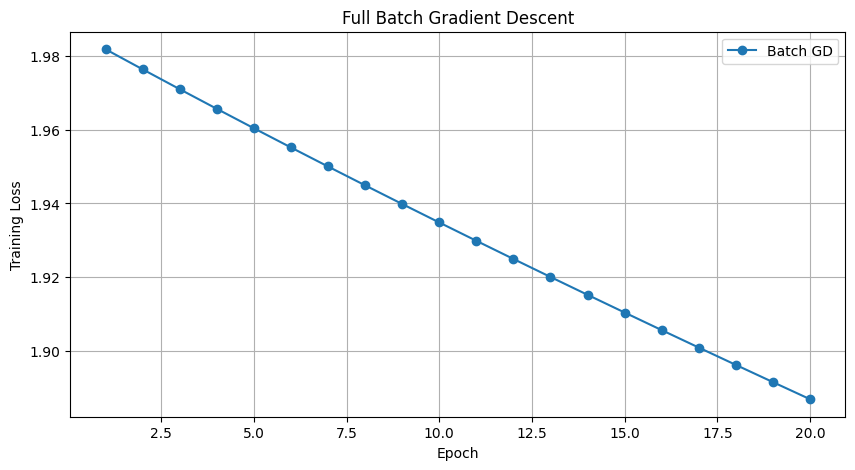

In [36]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, epochs + 1),
    loss_history_gd,
    marker='o',
    label='Batch GD'
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Full Batch Gradient Descent")
plt.legend()
plt.grid(True)

plt.show()

In [37]:
model_sgd = ForestNet().to(device)

model_sgd.load_state_dict(initial_weights)

criterion = nn.CrossEntropyLoss()

learning_rate = 0.01

# 5000 randomly selected training samples
torch.manual_seed(42)

indices = torch.randperm(len(X_train_tensor))[:5000]

X_sgd = X_train_tensor.to(device)
y_sgd = y_train_tensor.to(device)

print("SGD dataset:", X_sgd.shape)

SGD dataset: torch.Size([464809, 54])


In [38]:
loss_history_sgd = []

epochs_sgd = 1

for epoch in range(epochs_sgd):

    # Shuffle samples
    indices = torch.randperm(len(X_sgd), device=device)

    for idx in indices:

        # One sample
        x = X_sgd[idx].unsqueeze(0)
        y = y_sgd[idx].unsqueeze(0)

        # Clear previous gradients
        model_sgd.zero_grad()

        # Forward
        output = model_sgd(x)

        # Calculate loss
        loss = criterion(output, y)

        # Backward
        loss.backward()

        # Update weights
        with torch.no_grad():

            for param in model_sgd.parameters():

                param -= learning_rate * param.grad

        # Record loss before update
        loss_history_sgd.append(loss.item())

    print(
        f"Epoch [{epoch+1}/{epochs_sgd}] "
        f"Last Loss: {loss.item():.6f}"
    )

Epoch [1/1] Last Loss: 0.042414


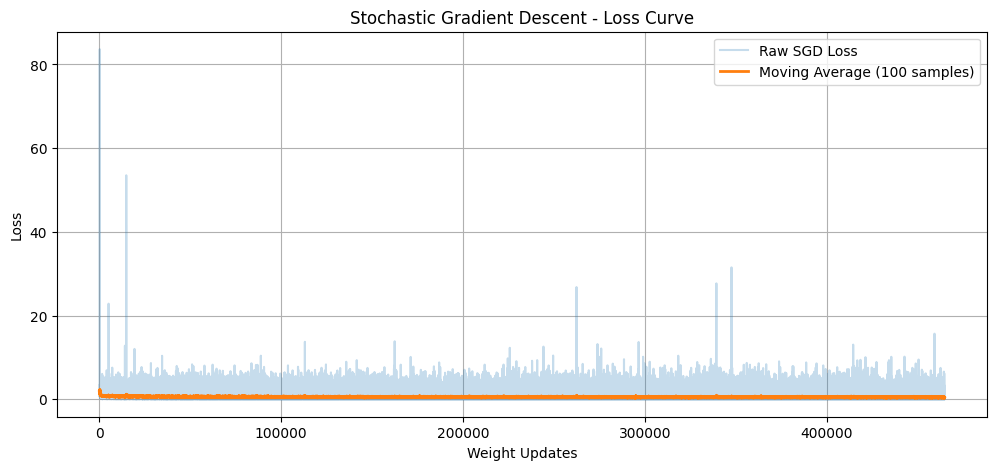

In [39]:
plt.figure(figsize=(12, 5))

plt.plot(
    loss_history_sgd,
    alpha=0.25,
    label="Raw SGD Loss"
)

# Moving average for visualization
window = 100

smooth_loss = np.convolve(
    loss_history_sgd,
    np.ones(window) / window,
    mode="valid"
)

plt.plot(
    range(window - 1, len(loss_history_sgd)),
    smooth_loss,
    linewidth=2,
    label="Moving Average (100 samples)"
)

plt.xlabel("Weight Updates")
plt.ylabel("Loss")

plt.title("Stochastic Gradient Descent - Loss Curve")

plt.legend()
plt.grid(True)
plt.show()

Epoch [1/5] | Avg Loss: 0.9562 | Time: 2.76 sec
Epoch [2/5] | Avg Loss: 0.6920 | Time: 2.56 sec
Epoch [3/5] | Avg Loss: 0.6547 | Time: 2.67 sec
Epoch [4/5] | Avg Loss: 0.6317 | Time: 2.67 sec
Epoch [5/5] | Avg Loss: 0.6137 | Time: 2.49 sec


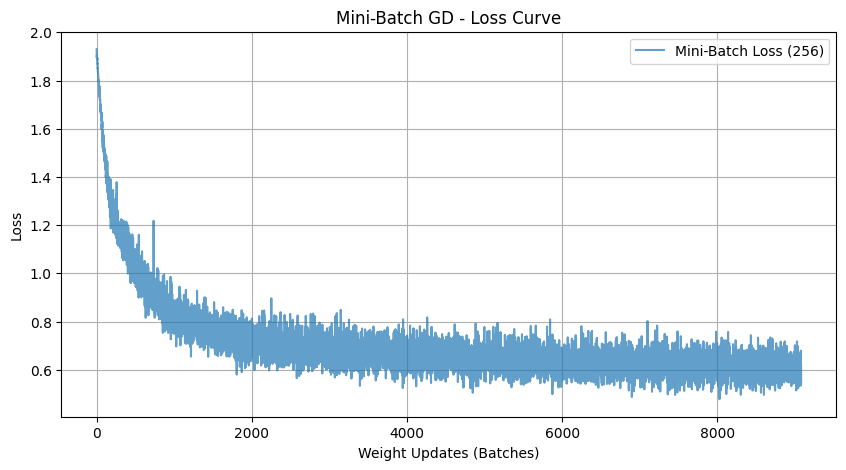

In [40]:
import torch
from torch.utils.data import DataLoader, TensorDataset
import time

# 1. DataLoader Setup (batch_size = 256)
batch_size = 256
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)  # Apne variable names yahan daalo
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# 2. Model, Loss, Optimizer (Fresh initialize karo benchmark ke liye)
model = ForestNet().to(device)
criterion = nn.CrossEntropyLoss() 
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# 3. Training Loop with Time & Loss Tracking
epochs = 5  # Pehle 5 epochs ke liye test karo
loss_history = []

for epoch in range(epochs):
    start_time = time.time()
    epoch_loss = 0.0
    
    for batch_X, batch_y in train_loader:
        # Move to GPU if available
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
        loss_history.append(loss.item()) # Har batch ka loss record kar rahe hain
    
    # Epoch time calculate karo
    torch.cuda.synchronize() # Wait for GPU to finish
    end_time = time.time()
    avg_loss = epoch_loss / len(train_loader)
    
    print(f"Epoch [{epoch+1}/{epochs}] | Avg Loss: {avg_loss:.4f} | Time: {end_time - start_time:.2f} sec")

# 4. Plotting Mini-Batch Loss
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(loss_history, label='Mini-Batch Loss (256)', alpha=0.7)
plt.title('Mini-Batch GD - Loss Curve')
plt.xlabel('Weight Updates (Batches)')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [42]:
import time

# Fresh model initialize karo (warna pichla trained model use hoga)
model = ForestNet().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

epochs = 50  # Full batch mein updates kam hote hain, isliye zyada epochs chahiye
batch_losses = []

start_full = time.time()

for epoch in range(epochs):
    # Poore dataset ko ek sath GPU mein daalo (baki data par bhi yehi karo)
    X_full, y_full = X_train_tensor.to(device), y_train_tensor.to(device)
    
    optimizer.zero_grad()
    outputs = model(X_full)
    loss = criterion(outputs, y_full)
    loss.backward()
    optimizer.step()
    
    batch_losses.append(loss.item())
    
    if (epoch+1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Loss: {loss.item():.4f}")

torch.cuda.synchronize()
end_full = time.time()

print(f"Total Time for {epochs} epochs: {end_full - start_full:.2f} sec")

Epoch [10/50] | Loss: 1.8703
Epoch [20/50] | Loss: 1.8200
Epoch [30/50] | Loss: 1.7711
Epoch [40/50] | Loss: 1.7234
Epoch [50/50] | Loss: 1.6768
Total Time for 50 epochs: 1.46 sec


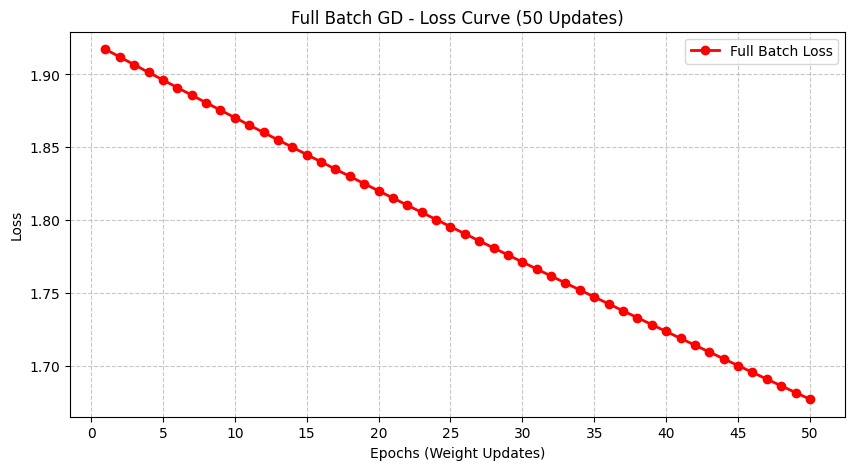

In [43]:
import matplotlib.pyplot as plt

# Full Batch GD ka plot
plt.figure(figsize=(10, 5))
plt.plot(range(1, epochs + 1), batch_losses, marker='o', color='red', linewidth=2, label='Full Batch Loss')

plt.title('Full Batch GD - Loss Curve (50 Updates)')
plt.xlabel('Epochs (Weight Updates)')
plt.ylabel('Loss')
plt.xticks(range(0, 51, 5)) # X-axis par 0, 5, 10... 50 dikhane ke liye
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()